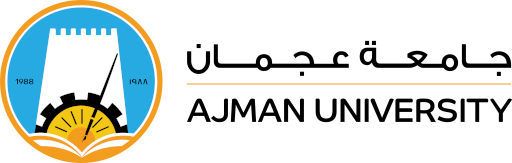

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

# **Lab 5 - Multilayer Perceptron MLP**

## Multi-Layer Perceptron
A multilayer perceptron (MLP) is a type of artificial neural network used in machine learning and deep learning. It is also commonly referred to as a feedforward neural network or a fully connected neural network. An MLP consists of multiple layers of interconnected artificial neurons, which are organized into three main types of layers:

Input Layer: The input layer receives the initial data or features that the network will process. Each neuron in this layer represents a single feature or input variable. The number of neurons in the input layer is determined by the dimensionality of the input data.

Hidden Layers: Between the input and output layers, there can be one or more hidden layers. These layers are called "hidden" because they are not directly connected to the outside world (input or output) and are responsible for learning complex patterns and representations from the input data. Each neuron in a hidden layer is connected to every neuron in the previous and subsequent layers, creating a dense or fully connected architecture.

Output Layer: The output layer produces the final results or predictions of the network. The number of neurons in the output layer depends on the specific task the MLP is designed for. For example, in a binary classification problem, there might be one neuron for binary classification, while in a multi-class classification problem, there would be one neuron per class.

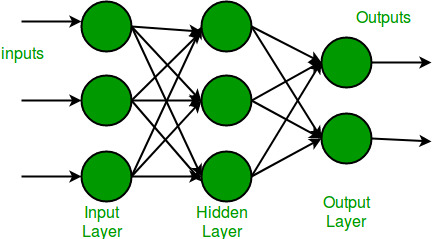

## MLP Implementation in Keras

### Primary Steps
1. Preparing the data
2. Defining the model architecture
3. Compiling the model
4. Training the model
5. Evaluating the model
6. Visualizing the model

In [4]:
# Loading the tensorboard notebook extension
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, BatchNormalization, Dropout
from keras.regularizers import l1,l2
from tensorflow.keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping

CIFAR10 Data Description:

https://www.cs.toronto.edu/~kriz/cifar.html#:~:text=The%20CIFAR%2D10%20dataset%20consists,batch%2C%20each%20with%2010000%20images.

In [ ]:
# -------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# -------------------------------------------------------------
# CIFAR-10 is a benchmark dataset for image classification.
# It contains 60,000 color images (32x32 pixels, RGB) in 10 classes:
# airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks.
# - 50,000 images are used for training
# - 10,000 images are used for testing

# The load_data() function automatically downloads the dataset if needed
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# After loading:
#  - x_train has shape (50000, 32, 32, 3)
#  - y_train has shape (50000, 1)
#  - x_test has shape (10000, 32, 32, 3)
#  - y_test has shape (10000, 1)

# -------------------------------------------------------------
# 2. Normalize image pixel values to range [0, 1]
# -------------------------------------------------------------
# The pixel values in CIFAR-10 images are integers between 0 and 255.
# Neural networks perform better and converge faster when input features
# are scaled to a smaller, consistent range — typically [0, 1] or [-1, 1].
# So we divide every pixel value by 255.0 to rescale them to [0, 1].
x_train = x_train / 255.0
x_test = x_test / 255.0

# After this operation:
#  - The shape of x_train and x_test remains the same
#  - But their data type changes from integer to float
#  - Each pixel now represents its brightness as a float between 0.0 and 1.0

# -------------------------------------------------------------
# 3. Convert class labels to one-hot encoded vectors
# -------------------------------------------------------------
# The CIFAR-10 labels are originally integers from 0 to 9.
# Example: a few labels might look like [6, 9, 9, 4, 1, ...]
#
# One-hot encoding converts each class label into a binary vector.
# For example, if there are 10 classes:
#  Label "3" -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
#  Label "7" -> [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
#
# This representation is required when using a softmax output layer
# and a categorical loss function (like categorical_crossentropy).
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# After encoding:
#  - y_train has shape (50000, 10)
#  - y_test has shape (10000, 10)
#  - Each row is a 10-dimensional vector representing one class


In [ ]:
# --------------------------------------------------------------
# Create a Sequential model
# --------------------------------------------------------------
# The Sequential model is a linear stack of layers.
# It allows you to build a neural network by adding layers one after another.
model = Sequential()

# --------------------------------------------------------------
# Add a Flatten layer to flatten the input image
# --------------------------------------------------------------
# CIFAR-10 images are 32x32 pixels with 3 color channels (RGB).
# The Flatten layer converts each 32x32x3 image (a 3D tensor) 
# into a 1D vector of size 32*32*3 = 3072.
# This transformation allows the data to be passed to the Dense (fully connected) layers.
model.add(Flatten(input_shape=(32, 32, 3)))

# --------------------------------------------------------------
# Add hidden Dense layers
# --------------------------------------------------------------
# A Dense layer is a fully connected neural network layer.
# Each neuron in this layer receives input from all neurons in the previous layer.

# First hidden layer:
# 128 neurons, using the ReLU (Rectified Linear Unit) activation function.
# ReLU introduces non-linearity and helps the model learn complex patterns.
model.add(Dense(128, activation='relu'))

# Second hidden layer:
# 64 neurons, also using ReLU activation.
# Adding more layers and neurons allows the network to learn more abstract representations.
model.add(Dense(64, activation='relu'))

# --------------------------------------------------------------
# Add the output layer
# --------------------------------------------------------------
# The output layer has 10 neurons, one for each CIFAR-10 class (e.g., airplane, car, bird, etc.).
# The softmax activation function converts the output into a probability distribution
# — meaning the sum of all 10 output values equals 1.
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# Display a summary of the model
# --------------------------------------------------------------
# The summary shows the structure of the model,
# including layer names, output shapes, and the number of trainable parameters.
model.summary()

In [ ]:
# --------------------------------------------------------------
# Define the optimizer
# --------------------------------------------------------------
# The Adam optimizer is an advanced optimization algorithm that combines
# the benefits of both SGD (Stochastic Gradient Descent) and RMSProp.
# It adapts the learning rate for each parameter automatically,
# which helps the model converge faster and more efficiently.
# Here, we explicitly set the learning rate to 0.0005 (a small value for stable training).
opt = optimizers.Adam(learning_rate=0.0005)

# --------------------------------------------------------------
# Compile the model
# --------------------------------------------------------------
# 'compile()' configures the model for training.
# It specifies:
#   - The loss function: measures how far predictions are from the true labels.
#   - The optimizer: determines how weights are updated to reduce the loss.
#   - The metrics: tells Keras which performance metrics to track during training and testing.

model.compile(
    loss='categorical_crossentropy',  # Used for multi-class classification problems
    optimizer=opt,                    # The Adam optimizer defined above
    metrics=['accuracy']              # Model performance will be measured by accuracy
)


In [ ]:
# --------------------------------------------------------------
# Logging the training process with TensorBoard
# --------------------------------------------------------------

# --------------------------------------------------------------
# Define the log directory
# --------------------------------------------------------------
# 'log_dir' is the folder where TensorBoard will store the training logs.
# These logs include information about loss, accuracy, learning rate, 
# and other metrics during training and validation.
# You can view these metrics in real-time using the TensorBoard dashboard.
log_dir = "logs/fit/"

# --------------------------------------------------------------
# Create a TensorBoard callback
# --------------------------------------------------------------
# A "callback" in Keras is a function that is executed at specific stages
# during training (e.g., after each epoch or batch).
# The TensorBoard callback automatically records all relevant training data
# into the specified log directory.
#
# Parameters:
# - log_dir: Path to save logs.
# - histogram_freq: How often (in epochs) to compute weight histograms
#   for visualization. Setting this to 1 means histograms will be logged
#   after every epoch.
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)


In [ ]:
# --------------------------------------------------------------
# Training the MLP (Multi-Layer Perceptron) model
# --------------------------------------------------------------

# Train the model using the training data
history = model.fit(
    x_train,                # Input features (images) for training
    y_train,                # Target labels (one-hot encoded)
    batch_size=64,          # Number of samples processed before the model updates weights
    epochs=20,              # Number of full passes through the training data
    shuffle=True,           # Shuffle data at the start of each epoch to improve generalization
    validation_split=0.2,   # Use 20% of the training data for validation (monitor overfitting)
    callbacks=[tensorboard_callback]  # Log training metrics for TensorBoard visualization
)


In [ ]:
# --------------------------------------------------------------
# Evaluate the MLP model on the test dataset
# --------------------------------------------------------------

# Evaluate the model's performance using the unseen test data
# This step checks how well the model generalizes to new, unseen examples.
# The method returns the values for the loss and metrics (in this case, accuracy).
loss, accuracy = model.evaluate(x_test, y_test)

# --------------------------------------------------------------
# Display the evaluation results
# --------------------------------------------------------------
# 'loss' represents the average error of the model on the test set.
# 'accuracy' represents the proportion of correctly predicted test samples.
print('Test loss:', loss)
print('Test accuracy:', accuracy)


In [ ]:
# --------------------------------------------------------------
# Visualizing the training process in TensorBoard
# --------------------------------------------------------------

# The %tensorboard command is specific to Jupyter Notebooks or Google Colab.
# It launches TensorBoard directly inside your notebook interface,
# allowing you to visualize the training metrics that were logged earlier.

# 'logdir' should point to the same folder used in the TensorBoard callback
# during model training (in this case, "logs/fit").
# This folder contains event files with recorded metrics like:
#  - training and validation loss
#  - training and validation accuracy
#  - histograms of weights and activations (if enabled)
#  - learning rate (if it changes over time)

%tensorboard --logdir=logs/fit


## Regularization Techniques

Regularization techniques in Keras, as in other machine learning frameworks, are methods used to prevent overfitting in neural networks. Overfitting occurs when a model performs well on the training data but fails to generalize to unseen data because it has learned noise or irrelevant patterns in the training data. Regularization helps mitigate this problem by adding a penalty term to the loss function, encouraging the model to have smaller weights or simpler architectures.

### Early Stopping
Early stopping is not a direct regularization technique, but it helps prevent overfitting by monitoring the model's performance on a validation dataset during training. Training is halted when the validation performance starts to degrade.

Let's implement Early Stopping callback to the code.

We added an EarlyStopping callback with the patience parameter set to 2. This means training will stop if the validation loss does not improve for 2 consecutive epochs.


In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# --------------------------------------------------------------
# CIFAR-10 is a dataset of 60,000 32x32 color images in 10 classes.
# 50,000 images are for training, 10,000 for testing.
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# --------------------------------------------------------------
# 2. Normalize pixel values
# --------------------------------------------------------------
# Original pixel values are integers between 0-255.
# Divide by 255.0 to scale values to the range [0,1] for better neural network training.
x_train = x_train / 255.0
x_test = x_test / 255.0

# --------------------------------------------------------------
# 3. One-hot encode class labels
# --------------------------------------------------------------
# Convert integer labels to one-hot vectors. Example for 10 classes:
# Label '3' -> [0,0,0,1,0,0,0,0,0,0]
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# --------------------------------------------------------------
# 4. Create the MLP (Multi-Layer Perceptron) model
# --------------------------------------------------------------
model = Sequential()

# Flatten input images (32x32x3) into 1D vectors of size 3072
model.add(Flatten(input_shape=(32, 32, 3)))

# First hidden layer: 128 neurons with ReLU activation
model.add(Dense(128, activation='relu'))

# Second hidden layer: 64 neurons with ReLU activation
model.add(Dense(64, activation='relu'))

# Output layer: 10 neurons (one per class) with softmax activation
# Softmax produces probabilities for multi-class classification
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 5. Compile the model
# --------------------------------------------------------------
# Adam optimizer: adaptive gradient algorithm
# Learning rate = 0.0005
# Loss = categorical crossentropy (used for multi-class classification)
# Metrics = accuracy
opt = optimizers.Adam(learning_rate=0.0005)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# --------------------------------------------------------------
# 6. Configure callbacks
# --------------------------------------------------------------
# TensorBoard callback: logs metrics for visualization
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# EarlyStopping callback: stops training if validation loss doesn't improve
# for 2 consecutive epochs (patience=2)
early_stopping_callback = EarlyStopping(monitor='val_loss', patience=2)

# --------------------------------------------------------------
# 7. Train the model
# --------------------------------------------------------------
# Parameters:
# - batch_size=64: number of samples per weight update
# - epochs=20: maximum number of passes through the training data
# - shuffle=True: shuffle training data each epoch
# - validation_split=0.2: use 20% of training data for validation
# - callbacks: TensorBoard and EarlyStopping
model.fit(
    x_train, 
    y_train, 
    batch_size=64, 
    epochs=20, 
    shuffle=True, 
    validation_split=0.2, 
    callbacks=[tensorboard_callback, early_stopping_callback]
)

# --------------------------------------------------------------
# 8. Evaluate the model on the test set
# --------------------------------------------------------------
# Returns the test loss and accuracy
loss, accuracy = model.evaluate(x_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)


In [ ]:
# --------------------------------------------------------------
# Launch TensorBoard inside a Jupyter Notebook or Google Colab
# --------------------------------------------------------------

# %tensorboard is a command available in Jupyter/Colab.
# It launches TensorBoard directly within the notebook interface.
# The '--logdir' argument specifies the folder where TensorBoard
# will read training logs (metrics, losses, weights, etc.).
%tensorboard --logdir=logs/fit

### Batch Normalization
While primarily used for improving training speed and stability, batch normalization can also act as a form of regularization. It normalizes the activations of each layer and reduces internal covariate shift, helping the model generalize better.

In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# --------------------------------------------------------------
# CIFAR-10: 60,000 images, 32x32 pixels, RGB, 10 classes

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# --------------------------------------------------------------
# 2. Normalize pixel values
# --------------------------------------------------------------
# Original pixel values are 0-255 integers.
# Divide by 255.0 to scale them to [0,1] for better neural network training.
x_train = x_train / 255.0
x_test = x_test / 255.0

# --------------------------------------------------------------
# 3. One-hot encode class labels
# --------------------------------------------------------------
# Converts integer labels into binary vectors for softmax classification
# Example: label 3 -> [0,0,0,1,0,0,0,0,0,0]
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# --------------------------------------------------------------
# 4. Create the MLP (Multi-Layer Perceptron) model
# --------------------------------------------------------------

model = Sequential()

# Flatten input images (32x32x3) into 1D vector (3072)
model.add(Flatten(input_shape=(32, 32, 3)))

# First hidden layer: 128 neurons, ReLU activation
model.add(Dense(128, activation='relu'))

# Batch Normalization after first hidden layer
# Normalizes outputs of the layer to stabilize and accelerate training
model.add(BatchNormalization())

# Second hidden layer: 64 neurons, ReLU activation
model.add(Dense(64, activation='relu'))

# Batch Normalization after second hidden layer
model.add(BatchNormalization())

# Output layer: 10 neurons (one per class), softmax activation
# Produces probabilities for multi-class classification
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 5. Compile the model
# --------------------------------------------------------------
# Adam optimizer with learning rate 0.0005
# Loss: categorical_crossentropy for multi-class classification
# Metric: accuracy to monitor training
opt = optimizers.Adam(learning_rate=0.0005)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# --------------------------------------------------------------
# 6. TensorBoard callback
# --------------------------------------------------------------
# Logs training metrics for visualization
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# --------------------------------------------------------------
# 7. Train the model
# --------------------------------------------------------------
# batch_size=64: number of samples per weight update
# epochs=20: maximum passes over training data
# shuffle=True: shuffle data each epoch
# validation_split=0.2: 20% of training data used for validation
# callbacks: TensorBoard to log metrics
model.fit(
    x_train, 
    y_train, 
    batch_size=64, 
    epochs=20, 
    shuffle=True, 
    validation_split=0.2, 
    callbacks=[tensorboard_callback]
)

# --------------------------------------------------------------
# 8. Evaluate the model on the test dataset
# --------------------------------------------------------------
# Returns test loss and accuracy (model generalization)
loss, accuracy = model.evaluate(x_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)


In [ ]:
# --------------------------------------------------------------
# Launch TensorBoard inside a Jupyter Notebook or Google Colab
# --------------------------------------------------------------

# %tensorboard is a command available in Jupyter/Colab.
# It launches TensorBoard directly within the notebook interface.
# The '--logdir' argument specifies the folder where TensorBoard
# will read training logs (metrics, losses, weights, etc.).
%tensorboard --logdir=logs/fit

### Dropout
Dropout is a regularization technique that randomly drops a fraction of the neurons during training. This helps prevent co-adaptation of neurons and makes the model more robust. In Keras, you can add dropout layers using the Dropout layer.

In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# --------------------------------------------------------------
# CIFAR-10: 60,000 images, 32x32 pixels, RGB, 10 classes
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# --------------------------------------------------------------
# 2. Normalize pixel values
# --------------------------------------------------------------
# Original pixel values range from 0 to 255
# Divide by 255.0 to scale them to [0,1] for better training stability
x_train = x_train / 255.0
x_test = x_test / 255.0

# --------------------------------------------------------------
# 3. One-hot encode labels
# --------------------------------------------------------------
# Converts integer labels into binary vectors for multi-class classification
# Example: label 3 -> [0,0,0,1,0,0,0,0,0,0]
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# --------------------------------------------------------------
# 4. Create the MLP model
# --------------------------------------------------------------
model = Sequential()

# Flatten input images (32x32x3) into 1D vector (3072)
model.add(Flatten(input_shape=(32, 32, 3)))

# First hidden layer: 128 neurons, ReLU activation
model.add(Dense(128, activation='relu'))

# Dropout layer with rate 0.5
# Randomly sets 50% of the neurons to zero during training
# Helps prevent overfitting by forcing the network to learn redundant representations
model.add(Dropout(0.5))

# Second hidden layer: 64 neurons, ReLU activation
model.add(Dense(64, activation='relu'))

# Dropout layer with rate 0.3
# Randomly sets 30% of neurons to zero during training
model.add(Dropout(0.3))

# Output layer: 10 neurons (one per class), softmax activation
# Produces class probabilities for multi-class classification
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 5. Compile the model
# --------------------------------------------------------------
# Adam optimizer with learning rate 0.0005
# Loss: categorical crossentropy for multi-class classification
# Metric: accuracy to track performance
opt = optimizers.Adam(learning_rate=0.0005)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# --------------------------------------------------------------
# 6. Configure TensorBoard callback
# --------------------------------------------------------------
# Logs training metrics for visualization
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# --------------------------------------------------------------
# 7. Train the model
# --------------------------------------------------------------
# Parameters:
# - batch_size=64: number of samples per weight update
# - epochs=20: maximum number of passes over the training data
# - shuffle=True: shuffle data each epoch to improve generalization
# - validation_split=0.2: 20% of training data used for validation
# - callbacks: TensorBoard logging
model.fit(
    x_train, 
    y_train, 
    batch_size=64, 
    epochs=20, 
    shuffle=True, 
    validation_split=0.2, 
    callbacks=[tensorboard_callback]
)

# --------------------------------------------------------------
# 8. Evaluate the model on the test dataset
# --------------------------------------------------------------
# Returns test loss and accuracy to assess generalization
loss, accuracy = model.evaluate(x_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)


In [ ]:
# --------------------------------------------------------------
# Launch TensorBoard inside a Jupyter Notebook or Google Colab
# --------------------------------------------------------------

# %tensorboard is a command available in Jupyter/Colab.
# It launches TensorBoard directly within the notebook interface.
# The '--logdir' argument specifies the folder where TensorBoard
# will read training logs (metrics, losses, weights, etc.).
%tensorboard --logdir=logs/fit

### L1 Regularization (Lasso)
L1 regularization adds a penalty term to the loss function that is proportional to the absolute values of the model's weights. It encourages the model to have sparse weights, effectively selecting a subset of the most important features. In Keras, you can apply L1 regularization to layers using the kernel_regularizer argument.

In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# --------------------------------------------------------------

# Load training and testing data
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# --------------------------------------------------------------
# 2. Normalize pixel values
# --------------------------------------------------------------
# Original pixel values range from 0 to 255
# Divide by 255.0 to scale them to [0,1] for faster and stable training
x_train = x_train / 255.0
x_test = x_test / 255.0

# --------------------------------------------------------------
# 3. One-hot encode class labels
# --------------------------------------------------------------
# Converts integer labels into binary vectors for multi-class classification
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# --------------------------------------------------------------
# 4. Create the MLP model with L1 regularization
# --------------------------------------------------------------
model = Sequential()

# Flatten input images (32x32x3) into 1D vector (3072)
model.add(Flatten(input_shape=(32, 32, 3)))

# First hidden layer: 128 neurons, ReLU activation, L1 regularization
# L1 regularization adds the absolute value of weights to the loss function
# Encourages sparsity (some weights become exactly zero)
model.add(Dense(128, activation='relu', kernel_regularizer=l1(0.01)))

# Second hidden layer: 64 neurons, ReLU activation, L1 regularization
model.add(Dense(64, activation='relu', kernel_regularizer=l1(0.01)))

# Output layer: 10 neurons (softmax for multi-class probabilities)
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 5. Compile the model
# --------------------------------------------------------------
# Adam optimizer with learning rate 0.0005
# Loss: categorical crossentropy for multi-class classification
# Metrics: accuracy to monitor performance
opt = optimizers.Adam(learning_rate=0.0005)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# --------------------------------------------------------------
# 6. TensorBoard callback for logging
# --------------------------------------------------------------
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# --------------------------------------------------------------
# 7. Train the model
# --------------------------------------------------------------
# batch_size=64: number of samples per weight update
# epochs=20: maximum passes over the training dataset
# shuffle=True: shuffle data each epoch for better generalization
# validation_split=0.2: 20% of training data used for validation
# callbacks: TensorBoard logging
model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=20,
    shuffle=True,
    validation_split=0.2,
    callbacks=[tensorboard_callback]
)

# --------------------------------------------------------------
# 8. Evaluate the model on test dataset
# --------------------------------------------------------------
# Returns test loss and accuracy to assess generalization
loss, accuracy = model.evaluate(x_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)

In [ ]:
# --------------------------------------------------------------
# Launch TensorBoard inside a Jupyter Notebook or Google Colab
# --------------------------------------------------------------

# %tensorboard is a command available in Jupyter/Colab.
# It launches TensorBoard directly within the notebook interface.
# The '--logdir' argument specifies the folder where TensorBoard
# will read training logs (metrics, losses, weights, etc.).
%tensorboard --logdir=logs/fit

### L2 Regularization (Ridge)
L2 regularization adds a penalty term to the loss function that is proportional to the square of the model's weights. It encourages the model to have small weights, preventing any one weight from becoming excessively large. In Keras, you can apply L2 regularization to layers using the kernel_regularizer argument.

In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Load the CIFAR-10 dataset
# --------------------------------------------------------------

# Load training and test sets
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# --------------------------------------------------------------
# 2. Normalize pixel values
# --------------------------------------------------------------
# Original pixels are integers in [0, 255].
# Divide by 255.0 to scale them to [0, 1] for neural network training.
x_train = x_train / 255.0
x_test = x_test / 255.0

# --------------------------------------------------------------
# 3. One-hot encode class labels
# --------------------------------------------------------------
# Converts integer labels into binary vectors for multi-class classification
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# --------------------------------------------------------------
# 4. Create the MLP model with L2 regularization
# --------------------------------------------------------------
model = Sequential()

# Flatten input images (32x32x3) into 1D vector (3072)
model.add(Flatten(input_shape=(32, 32, 3)))

# First hidden layer: 128 neurons, ReLU activation, L2 regularization
# L2 adds the squared sum of weights to the loss function
# Penalizes large weights and encourages smaller weight values to prevent overfitting
model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))

# Second hidden layer: 64 neurons, ReLU activation, L2 regularization
model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))

# Output layer: 10 neurons (softmax) for multi-class probabilities
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 5. Compile the model
# --------------------------------------------------------------
# Adam optimizer with learning rate 0.0005
# Loss: categorical crossentropy
# Metric: accuracy
opt = optimizers.Adam(learning_rate=0.0005)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# --------------------------------------------------------------
# 6. TensorBoard callback
# --------------------------------------------------------------
# Logs training metrics for visualization in TensorBoard
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# --------------------------------------------------------------
# 7. Train the model
# --------------------------------------------------------------
# batch_size=64: number of samples per weight update
# epochs=20: number of passes through the training data
# shuffle=True: shuffle training data each epoch
# validation_split=0.2: use 20% of training data for validation
model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=20,
    shuffle=True,
    validation_split=0.2,
    callbacks=[tensorboard_callback]
)

# --------------------------------------------------------------
# 8. Evaluate the model on the test dataset
# --------------------------------------------------------------
# Returns test loss and accuracy to check generalization
loss, accuracy = model.evaluate(x_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)

In [ ]:
# --------------------------------------------------------------
# Launch TensorBoard inside a Jupyter Notebook or Google Colab
# --------------------------------------------------------------

# %tensorboard is a command available in Jupyter/Colab.
# It launches TensorBoard directly within the notebook interface.
# The '--logdir' argument specifies the folder where TensorBoard
# will read training logs (metrics, losses, weights, etc.).
%tensorboard --logdir=logs/fit

# QUESTION
1. You are given the following MLP architecture for classifying the MNIST dataset. Train the network with different regularization techniques, and discuss the results.

In [ ]:
!rm -rf /content/logs

In [ ]:
# --------------------------------------------------------------
# 1. Import libraries
# --------------------------------------------------------------
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
import keras

# --------------------------------------------------------------
# 2. Load MNIST dataset
# --------------------------------------------------------------
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# --------------------------------------------------------------
# 3. Normalize pixel values
# --------------------------------------------------------------
X_train = X_train.astype('float32') / 255.0  # scale to [0,1]
X_test = X_test.astype('float32') / 255.0

# --------------------------------------------------------------
# 4. One-hot encode labels (10 classes)
# --------------------------------------------------------------
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# --------------------------------------------------------------
# 5. Create MLP model
# --------------------------------------------------------------
model = Sequential()

# Flatten 28x28 input images into 784-dimensional vector
model.add(Flatten(input_shape=(28,28)))

# First hidden layer: 128 neurons, ReLU, L2 regularization
model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))

# Second hidden layer: 64 neurons, ReLU, L2 regularization
model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))

# Output layer: 10 neurons, softmax activation
model.add(Dense(10, activation='softmax'))

# --------------------------------------------------------------
# 6. Compile the model
# --------------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# --------------------------------------------------------------
# 7. TensorBoard callback
# --------------------------------------------------------------
log_dir = "logs/fit/"
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# --------------------------------------------------------------
# 8. Train the model
# --------------------------------------------------------------
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,   # 20% of training data for validation
    callbacks=[tensorboard_callback]
)

# --------------------------------------------------------------
# 9. Evaluate the model on test dataset
# --------------------------------------------------------------
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy * 100:.2f}%")
